# Week 5 Electricity Consumption Analysis

## Dataset inspection and quality checks

The supplied dataset contains 52,416 rows and 9 columns. No missing values, duplicate rows, or duplicate timestamps were found. The Datetime column was parsed successfully and is already in chronological order. It covers 1 January 2017 to 30 December 2017, with all 52,415 intervals between readings equal to 10 minutes.

The IQR check flagged 7 Zone 2 readings and 1,191 Zone 3 readings as potential high-value outliers. Reviewed examples showed sustained evening peaks across the zones, so the readings were retained.

The UCI dataset record confirms the 10-minute observation interval but does not specify measurement units for the consumption or diffuse-flow columns. These values will not be treated as energy totals without unit confirmation.

**Source:** Salam, A., & El Hibaoui, A. (2018). *Power Consumption of Tetouan City* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5B034

In [1]:
import pandas as pd

file_path = r"C:\Users\akubu\Downloads\powerconsumption.csv"
df = pd.read_csv(file_path)

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (52416, 9)


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [2]:
df.info()
print("\nMissing values per column:")
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Datetime                52416 non-null  str    
 1   Temperature             52416 non-null  float64
 2   Humidity                52416 non-null  float64
 3   WindSpeed               52416 non-null  float64
 4   GeneralDiffuseFlows     52416 non-null  float64
 5   DiffuseFlows            52416 non-null  float64
 6   PowerConsumption_Zone1  52416 non-null  float64
 7   PowerConsumption_Zone2  52416 non-null  float64
 8   PowerConsumption_Zone3  52416 non-null  float64
dtypes: float64(8), str(1)
memory usage: 4.3 MB

Missing values per column:
Datetime                  0
Temperature               0
Humidity                  0
WindSpeed                 0
GeneralDiffuseFlows       0
DiffuseFlows              0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zon

In [3]:
print("Duplicate full rows:", df.duplicated().sum())
print("Duplicate timestamps:", df["Datetime"].duplicated().sum())

Duplicate full rows: 0
Duplicate timestamps: 0


In [4]:
df_analysis = df.copy()
df_analysis["Datetime"] = pd.to_datetime(
    df_analysis["Datetime"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

print("Unparsed dates:", df_analysis["Datetime"].isna().sum())
print("First date:", df_analysis["Datetime"].min())
print("Last date:", df_analysis["Datetime"].max())
print("Already in time order:", df_analysis["Datetime"].is_monotonic_increasing)

Unparsed dates: 0
First date: 2017-01-01 00:00:00
Last date: 2017-12-30 23:50:00
Already in time order: True


In [5]:
intervals = df_analysis["Datetime"].diff().dropna()

print("Most common intervals:")
print(intervals.value_counts().head())
print("Intervals not equal to 10 minutes:",
      (intervals != pd.Timedelta(minutes=10)).sum())

Most common intervals:
Datetime
0 days 00:10:00    52415
Name: count, dtype: int64
Intervals not equal to 10 minutes: 0


In [6]:
df_analysis.select_dtypes(include="number").describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Temperature,52416.0,18.81,5.82,3.25,14.41,18.78,22.89,40.01
Humidity,52416.0,68.26,15.55,11.34,58.31,69.86,81.40,94.80
WindSpeed,52416.0,1.96,2.35,0.05,0.08,0.09,4.92,6.48
GeneralDiffuseFlows,52416.0,182.70,264.40,0.00,0.06,5.04,319.60,1163.00
DiffuseFlows,52416.0,75.03,124.21,0.01,0.12,4.46,101.00,936.00
PowerConsumption_Zone1,52416.0,32344.97,7130.56,13895.70,26310.67,32265.92,37309.02,52204.40
PowerConsumption_Zone2,52416.0,21042.51,5201.47,8560.08,16980.77,20823.17,24713.72,37408.86
PowerConsumption_Zone3,52416.0,17835.41,6622.17,5935.17,13129.33,16415.12,21624.10,47598.33


In [7]:
zone_cols = [
    "PowerConsumption_Zone1",
    "PowerConsumption_Zone2",
    "PowerConsumption_Zone3"
]

for col in zone_cols:
    q1 = df_analysis[col].quantile(0.25)
    q3 = df_analysis[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    candidates = ((df_analysis[col] < lower) | (df_analysis[col] > upper)).sum()
    print(f"{col}: {candidates} possible outliers")

PowerConsumption_Zone1: 0 possible outliers
PowerConsumption_Zone2: 7 possible outliers
PowerConsumption_Zone3: 1191 possible outliers


In [30]:
import numpy as np

zone_data = df_analysis[zone_cols].to_numpy()

print("Mean by zone:", np.mean(zone_data, axis=0).round(2))
print("Median by zone:", np.median(zone_data, axis=0).round(2))
print("25th, 50th, and 75th percentiles by zone:")
print(np.percentile(zone_data, [25, 50, 75], axis=0).round(2))

Mean by zone: [32344.97 21042.51 17835.41]
Median by zone: [32265.92 20823.17 16415.12]
25th, 50th, and 75th percentiles by zone:
[[26310.67 16980.77 13129.33]
 [32265.92 20823.17 16415.12]
 [37309.02 24713.72 21624.1 ]]


In [8]:
col = "PowerConsumption_Zone3"
q1 = df_analysis[col].quantile(0.25)
q3 = df_analysis[col].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)

print("Upper IQR fence:", round(upper, 2))
display(
    df_analysis.nlargest(5, col)[["Datetime", col]]
)

Upper IQR fence: 34366.26


,Datetime,PowerConsumption_Zone3
29497,2017-07-24 20:10:00,47598.32636
29929,2017-07-27 20:10:00,47598.32636
29784,2017-07-26 20:00:00,47580.25105
29785,2017-07-26 20:10:00,47507.94979
29786,2017-07-26 20:20:00,47441.67364


In [9]:
display(
    df_analysis.loc[
        29782:29788,
        ["Datetime", "PowerConsumption_Zone1",
         "PowerConsumption_Zone2", "PowerConsumption_Zone3"]
    ]
)

,Datetime,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
29782,2017-07-26 19:40:00,47980.86379,33748.10127,46164.35146
29783,2017-07-26 19:50:00,49505.38206,34594.93671,47291.04603
29784,2017-07-26 20:00:00,50474.95017,34731.64557,47580.25105
29785,2017-07-26 20:10:00,50685.44850,34651.89873,47507.94979
29786,2017-07-26 20:20:00,50800.26578,34651.89873,47441.67364
29787,2017-07-26 20:30:00,50742.85714,34420.25316,47074.14226
29788,2017-07-26 20:40:00,50328.23920,34010.12658,46796.98745


In [10]:
col = "PowerConsumption_Zone2"
q1 = df_analysis[col].quantile(0.25)
q3 = df_analysis[col].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)

flagged = df_analysis[df_analysis[col] > upper]
print("Upper IQR fence:", round(upper, 2))
display(flagged[[
    "Datetime", "PowerConsumption_Zone1",
    "PowerConsumption_Zone2", "PowerConsumption_Zone3"
]])

Upper IQR fence: 36313.14


,Datetime,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
29493,2017-07-24 19:30:00,45327.30897,36645.56962,38723.34728
29494,2017-07-24 19:40:00,48676.14618,37408.86076,45857.07113
30935,2017-08-03 19:50:00,48765.01665,36429.56705,38159.24765
30936,2017-08-03 20:00:00,48880.08879,36482.78775,38381.94357
30937,2017-08-03 20:10:00,49289.23418,36353.53749,38544.45141
30938,2017-08-03 20:20:00,49666.41509,36437.17001,38496.30094
30939,2017-08-03 20:30:00,49570.52164,36391.55227,38297.68025


In [11]:
dt = df_analysis["Datetime"]

df_analysis["Year"] = dt.dt.year
df_analysis["Month"] = dt.dt.month
df_analysis["Day"] = dt.dt.day
df_analysis["Hour"] = dt.dt.hour
df_analysis["DayOfWeek"] = dt.dt.day_name()
df_analysis["Date"] = dt.dt.date

df_analysis.head()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3,Year,Month,Day,Hour,DayOfWeek,Date
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386,2017,1,1,0,Sunday,2017-01-01
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434,2017,1,1,0,Sunday,2017-01-01
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373,2017,1,1,0,Sunday,2017-01-01
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711,2017,1,1,0,Sunday,2017-01-01
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964,2017,1,1,0,Sunday,2017-01-01


## Average Recorded Consumption by Zone

In [12]:
zone_cols = [
    "PowerConsumption_Zone1",
    "PowerConsumption_Zone2",
    "PowerConsumption_Zone3"
]

df_analysis[zone_cols].mean().round(2)

PowerConsumption_Zone1    32344.97
PowerConsumption_Zone2    21042.51
PowerConsumption_Zone3    17835.41
dtype: float64

In [13]:
hourly_avg = df_analysis.groupby("Hour")[zone_cols].mean()

for zone in zone_cols:
    print(
        zone,
        "| highest average hour:", hourly_avg[zone].idxmax(),
        "| lowest average hour:", hourly_avg[zone].idxmin()
    )

PowerConsumption_Zone1 | highest average hour: 20 | lowest average hour: 6
PowerConsumption_Zone2 | highest average hour: 20 | lowest average hour: 6
PowerConsumption_Zone3 | highest average hour: 20 | lowest average hour: 7


### Hourly Pattern

The average recorded value was highest at 20:00 in all three zones. The lowest average was at 06:00 in Zones 1 and 2, and at 07:00 in Zone 3. Measurement units were not specified, so these are comparisons of recorded values.

In [14]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_avg = (
    df_analysis.groupby("DayOfWeek")[zone_cols]
    .mean()
    .reindex(weekday_order)
    .round(2)
)

weekday_avg

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
DayOfWeek,,,
Monday,32615.41,21280.07,17809.08
Tuesday,32713.03,21518.60,17831.69
Wednesday,32871.76,21627.36,17851.40
Thursday,32842.48,21845.16,17843.69
Friday,32339.00,21461.04,17545.97
Saturday,32253.03,20585.96,18011.19
Sunday,30780.08,18979.38,17954.83


### Day-of-week pattern

Zone 1 had its highest average recorded value on Wednesday (32,871.76) and lowest on Sunday (30,780.08). Zone 2 was highest on Thursday (21,845.16) and lowest on Sunday (18,979.38). Zone 3 was highest on Saturday (18,011.19) and lowest on Friday (17,545.97). These are descriptive comparisons and do not establish the reasons for the differences.

In [15]:
month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_avg = (
    df_analysis.groupby("Month")[zone_cols]
    .mean()
    .reindex(range(1, 13))
    .round(2)
)

monthly_avg.index = month_names
monthly_avg

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Jan,31032.49,19394.44,17746.10
Feb,30985.75,18787.79,17335.00
Mar,31155.17,18457.94,16947.69
Apr,31169.77,17633.97,18593.17
May,32396.01,19977.29,17621.10
Jun,34605.54,20670.93,20430.94
Jul,35831.55,24147.89,28194.11
Aug,36435.19,24656.22,24648.89
Sep,33396.68,20180.43,14922.80
Oct,32827.66,21468.99,13264.10


### Monthly pattern

Zone 1 and Zone 2 had their highest monthly average recorded values in August; Zone 3 peaked in July. Their lowest monthly averages occurred in November, April, and December, respectively. These results describe month-to-month variation in 2017 and do not establish a recurring annual pattern.

In [16]:
weather_cols = ["Temperature", "Humidity", "WindSpeed"]

correlations = (
    df_analysis[weather_cols + zone_cols]
    .corr(method="pearson")
    .loc[weather_cols, zone_cols]
    .round(2)
)

correlations

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Temperature,0.44,0.38,0.49
Humidity,-0.29,-0.29,-0.23
WindSpeed,0.17,0.15,0.28


### Environmental correlations

Temperature had a moderate positive linear association with the recorded values in all three zones (Pearson r = 0.38–0.49). Humidity had a weak negative association (r = -0.23 to -0.29), while wind speed had a weak positive association (r = 0.15–0.28). These correlations do not establish causation and may also reflect time patterns or other factors.

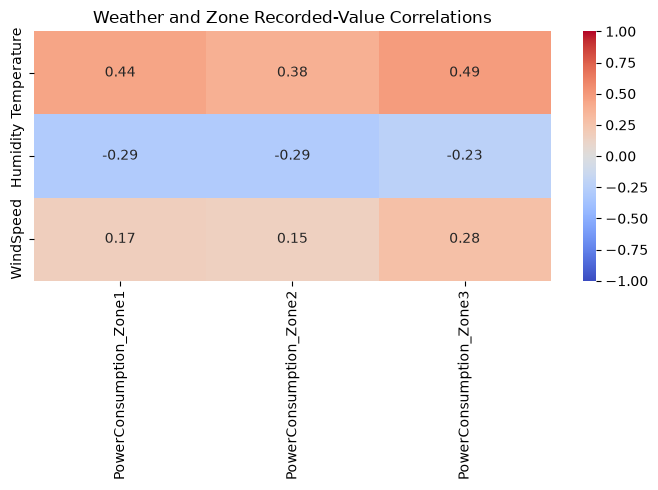

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlations,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Weather and Zone Recorded-Value Correlations")
plt.tight_layout()
plt.show()

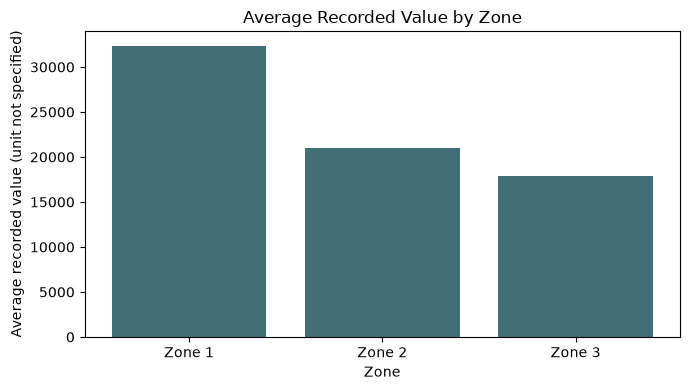

In [20]:
zone_means = df_analysis[zone_cols].mean()

plt.figure(figsize=(7, 4))
plt.bar(
    ["Zone 1", "Zone 2", "Zone 3"],
    zone_means.values,
    color="#426F77"
)
plt.title("Average Recorded Value by Zone")
plt.xlabel("Zone")
plt.ylabel("Average recorded value (unit not specified)")
plt.tight_layout()
plt.show()

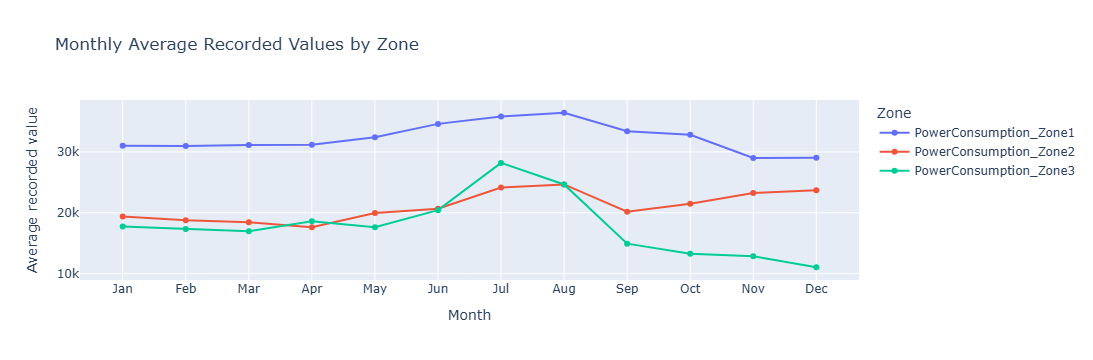

In [24]:
import plotly.express as px

monthly_plot = monthly_avg.copy()
monthly_plot.index.name = "Month"
monthly_plot = monthly_plot.reset_index()

monthly_long = monthly_plot.melt(
    id_vars="Month",
    var_name="Zone",
    value_name="Average recorded value"
)

fig = px.line(
    monthly_long,
    x="Month",
    y="Average recorded value",
    color="Zone",
    markers=True,
    title="Monthly Average Recorded Values by Zone"
)

fig.show()

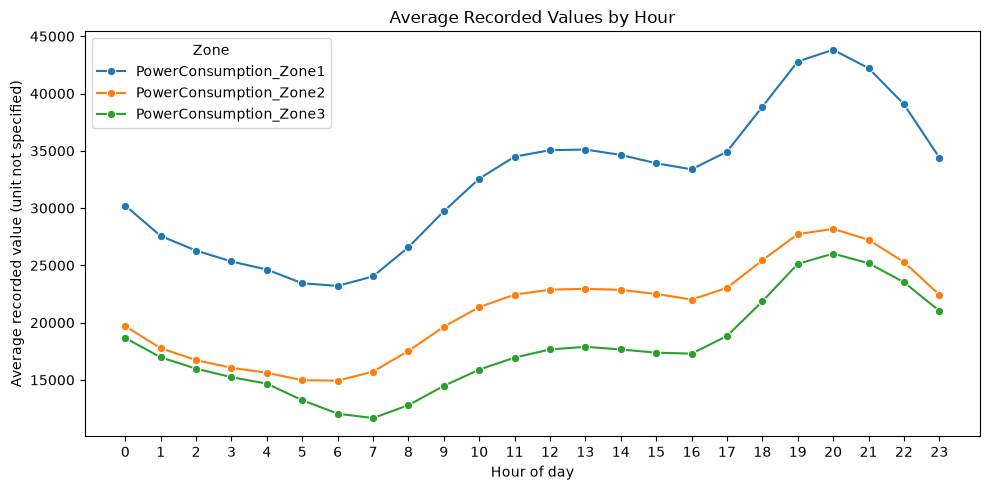

In [22]:
hourly_plot = hourly_avg.reset_index()

hourly_long = hourly_plot.melt(
    id_vars="Hour",
    var_name="Zone",
    value_name="Average recorded value"
)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=hourly_long,
    x="Hour",
    y="Average recorded value",
    hue="Zone",
    marker="o"
)
plt.xticks(range(24))
plt.title("Average Recorded Values by Hour")
plt.xlabel("Hour of day")
plt.ylabel("Average recorded value (unit not specified)")
plt.tight_layout()
plt.show()

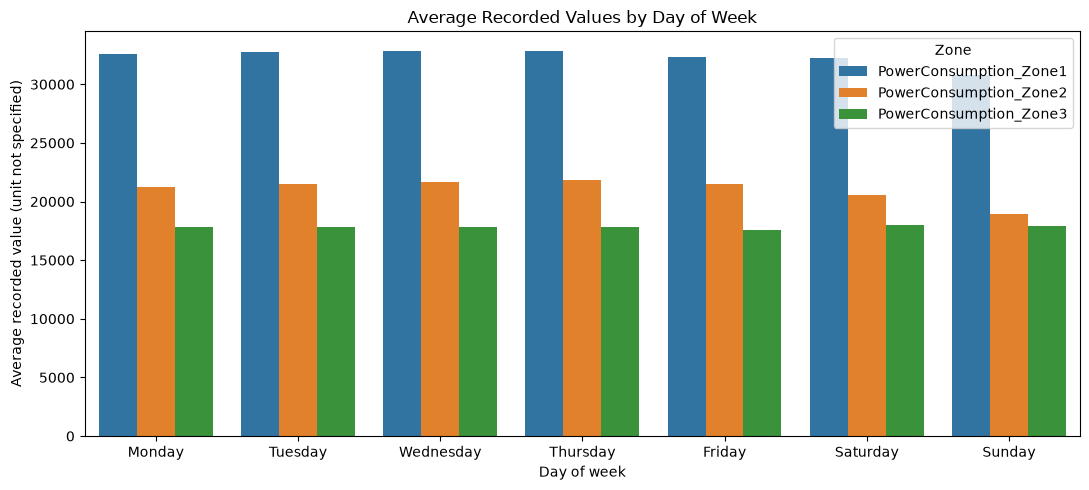

In [25]:
weekday_plot = weekday_avg.copy()
weekday_plot.index.name = "DayOfWeek"

weekday_long = weekday_plot.reset_index().melt(
    id_vars="DayOfWeek",
    var_name="Zone",
    value_name="Average recorded value"
)

plt.figure(figsize=(11, 5))
sns.barplot(
    data=weekday_long,
    x="DayOfWeek",
    y="Average recorded value",
    hue="Zone",
    order=weekday_order
)
plt.title("Average Recorded Values by Day of Week")
plt.xlabel("Day of week")
plt.ylabel("Average recorded value (unit not specified)")
plt.tight_layout()
plt.show()

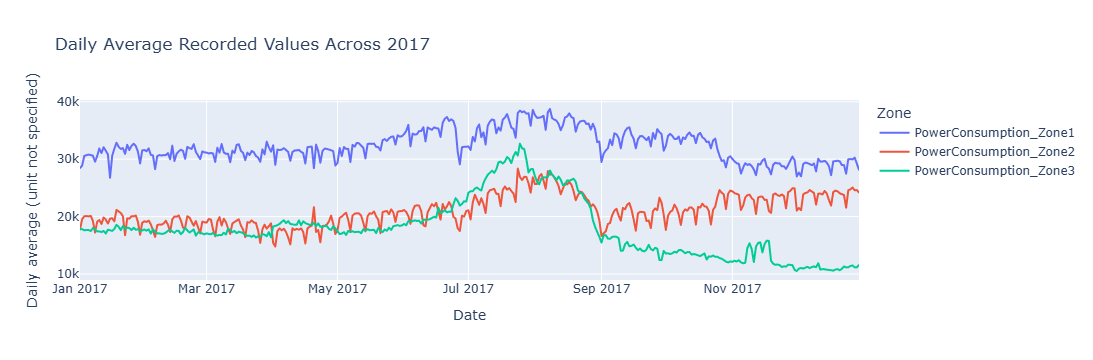

In [26]:
daily_avg = df_analysis.groupby("Date")[zone_cols].mean().reset_index()

daily_long = daily_avg.melt(
    id_vars="Date",
    var_name="Zone",
    value_name="Average recorded value"
)

fig = px.line(
    daily_long,
    x="Date",
    y="Average recorded value",
    color="Zone",
    title="Daily Average Recorded Values Across 2017",
    labels={"Date": "Date", "Average recorded value": "Daily average (unit not specified)"}
)

fig.show()

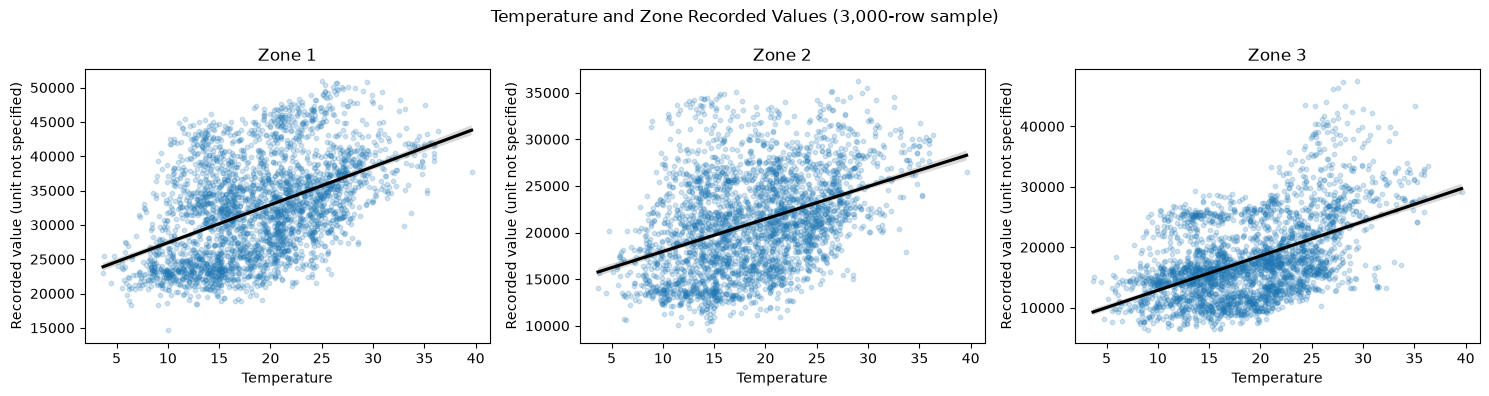

In [27]:
scatter_sample = df_analysis.sample(n=3000, random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, zone, label in zip(
    axes,
    zone_cols,
    ["Zone 1", "Zone 2", "Zone 3"]
):
    sns.regplot(
        data=scatter_sample,
        x="Temperature",
        y=zone,
        ax=ax,
        scatter_kws={"alpha": 0.2, "s": 10},
        line_kws={"color": "black"}
    )
    ax.set_title(label)
    ax.set_ylabel("Recorded value (unit not specified)")

fig.suptitle("Temperature and Zone Recorded Values (3,000-row sample)")
plt.tight_layout()
plt.show()

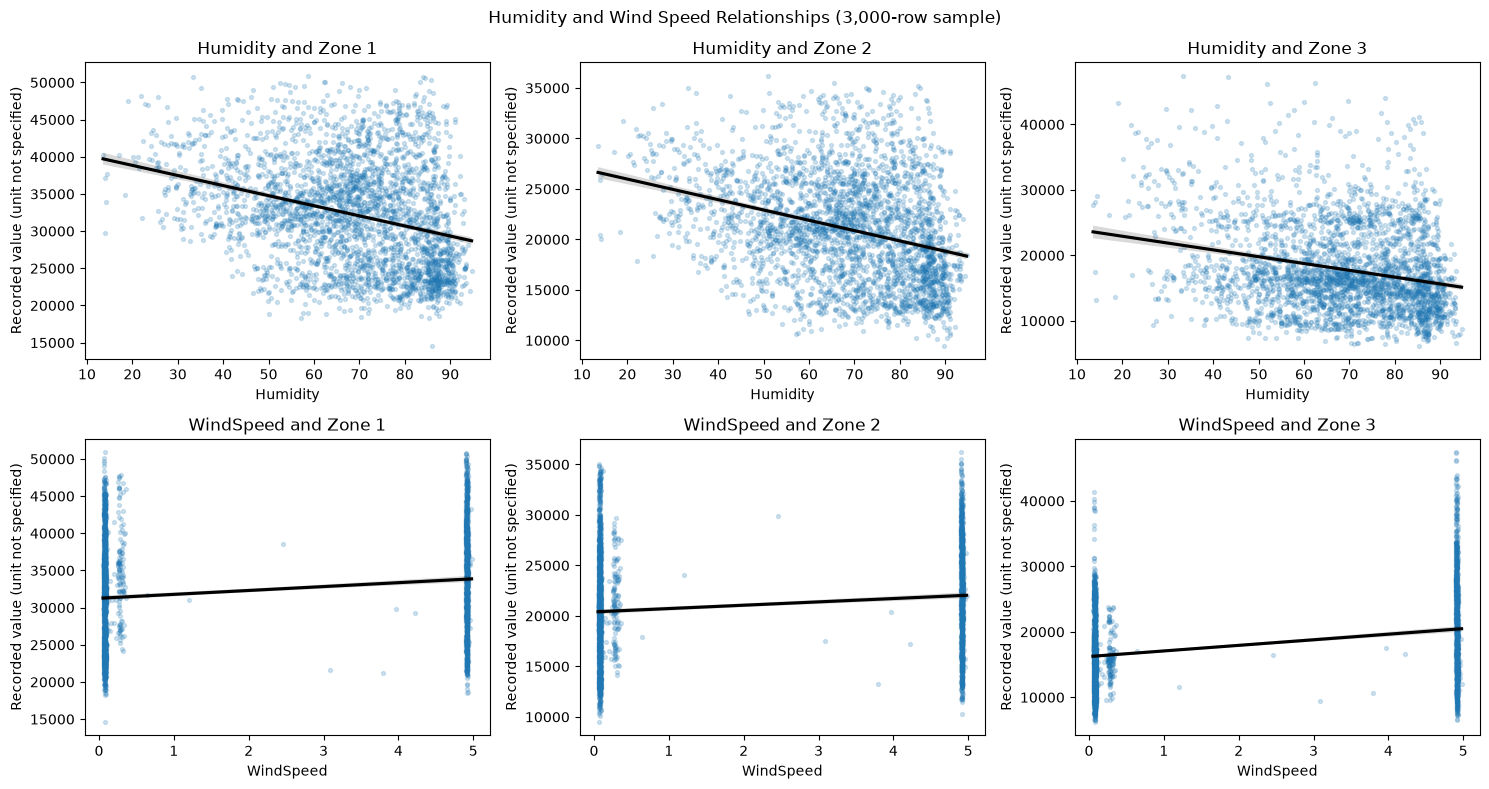

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for row, weather in enumerate(["Humidity", "WindSpeed"]):
    for col, (zone, label) in enumerate(zip(
        zone_cols,
        ["Zone 1", "Zone 2", "Zone 3"]
    )):
        ax = axes[row, col]
        sns.regplot(
            data=scatter_sample,
            x=weather,
            y=zone,
            ax=ax,
            scatter_kws={"alpha": 0.2, "s": 8},
            line_kws={"color": "black"}
        )
        ax.set_title(f"{weather} and {label}")
        ax.set_ylabel("Recorded value (unit not specified)")

fig.suptitle("Humidity and Wind Speed Relationships (3,000-row sample)")
plt.tight_layout()
plt.show()

## Business Insights and Recommendations

### Findings

1. **Average recorded values differed by zone.** Zone 1 had the highest average (32,344.97), followed by Zone 2 (21,042.51) and Zone 3 (17,835.41). Measurement units were not specified.

2. **The highest hourly average occurred at 20:00 in all three zones.** The lowest hourly averages occurred at 06:00 in Zones 1 and 2, and at 07:00 in Zone 3.

3. **Monthly patterns differed across zones.** Zone 1 and Zone 2 had their highest monthly averages in August, while Zone 3 peaked in July. The dataset covers one year, so these results describe 2017 and do not establish a recurring annual pattern.

4. **The weekday averages also differed by zone.** Zone 1 was highest on Wednesday and lowest on Sunday. Zone 2 was highest on Thursday and lowest on Sunday. Zone 3 was highest on Saturday and lowest on Friday.

5. **Temperature had a moderate positive linear association with recorded values.** Pearson correlations ranged from 0.38 to 0.49 across the zones. Humidity had weak negative correlations (-0.23 to -0.29), while wind speed had weak positive correlations (0.15 to 0.28). These relationships do not establish cause and effect.

### Recommendations

1. **Review the evening peak period.** Examine operating conditions around 20:00 in all three zones and assess whether demand-management actions or operational staffing should be adjusted.

2. **Use zone-specific monitoring and planning.** The zones have different average values and different weekday and monthly patterns, so review each zone separately when planning capacity and operational responses.

3. **Validate before using these results for energy targets or forecasts.** Confirm the measurement units and diffuse-flow definitions, and use additional years of data to test whether the 2017 monthly patterns repeat. Treat weather correlations as possible relationships to investigate, not proof of cause.
```**

In [31]:
cleaned_path = r"C:\Users\akubu\Downloads\powerconsumption_cleaned.csv"
df_analysis.to_csv(cleaned_path, index=False)

print("Saved cleaned dataset to:", cleaned_path)

Saved cleaned dataset to: C:\Users\akubu\Downloads\powerconsumption_cleaned.csv
